# 12. Outliers: finding the unusual people, and what to do with them

The theory class explained *how* Isolation Forest and LOF work. Here we ask the practical questions on our data:

1. Is an extreme value an error? (invalid ≠ extreme ≠ anomalous)
2. What does scikit-learn's Isolation Forest give us, and how does it map to the theory?
3. What changes with LOF: scaling, scoring **new** people, and choosing *k*
4. Do the two methods flag the same people?
5. What can we do with an anomaly, and where does it go in the pipeline?

At the end: the new `AnomalyScore` step and how to add it to your pipeline.

## 1 · Setup

`course_helpers.py` (next to this notebook) is **last week's pipeline in one file**: the same functions and the same `config.yaml`, so this notebook runs on its own and only this week's *new* code appears here. The data is in `data/`.

The detectors will run where the new step runs in the pipeline: **after the preprocessor** (gaps filled, numeric columns scaled, categories encoded). So we fit the preprocessor once on the development rows with `fit_transform` (exactly what the Pipeline does on training rows) and call its output `Z`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import Pipeline

from course_helpers import *        # last week's pipeline: build_preprocessor, cross_validate_pipeline, CONFIG, ...

pd.set_option("display.width", 140)
BLUE, ORANGE = "#2a78d6", "#eb6834"

X_dev, y_dev, extras_dev, cv = load_course_data()
prep = build_preprocessor(CONFIG["preprocessing"])
Z = prep.fit_transform(X_dev, y_dev)        # what the Pipeline does on training rows

numeric = CONFIG["preprocessing"]["numeric_features"]
show = numeric + ["sex", "c_charge_degree"]
print(X_dev.shape, "->", Z.shape)

(5771, 10) -> (5771, 10)


## 2 · Invalid ≠ extreme ≠ anomalous

| | Example | What the pipeline does |
|---|---|---|
| **Invalid** | age 150, priors −3 | breaks a domain rule → `validity_rules` already turn it into a gap |
| **Extreme** | 38 priors | a valid value far in the tail of **one** column |
| **Anomalous** | 18 years old with 5 juvenile felonies and 4 priors | each value is plausible; the **combination** is rare |

**Someone with 30 or more priors. An error?**

In [2]:
many = X_dev["priors_count"] >= 30
print(f"{many.sum()} people with 30+ priors")
X_dev.loc[many, show]

6 people with 30+ priors


,age,juv_fel_count,juv_misd_count,juv_other_count,priors_count,sex,c_charge_degree
2215,39.0,0.0,0,0,35.0,Male,F
1747,56.0,0.0,0,0,31.0,Male,F
2888,53.0,0.0,0,0,36.0,Male,F
538,58.0,0.0,0,0,38.0,Male,F
1750,61.0,0.0,0,0,30.0,Male,F
511,45.0,0.0,0,0,38.0,Male,F


They are all adults aged 39–61: decades of record. **Extreme, not wrong.** Deleting them would delete exactly the people the model should recognise, and a deployed model can't delete a person anyway. Our `validity_rules` cap `priors_count` at 60: above that it's treated as an error.

So the question is not "how do I remove outliers?" but "**how unusual is each person, and is that useful?**". That's what the detectors measure.

## 3 · Isolation Forest in scikit-learn

![Isolation Forest](images/isolation_forest.png)

| Theory | scikit-learn |
|---|---|
| *t* trees | `n_estimators=100` (default) |
| subsample size ψ | `max_samples=256` (default: `min(256, n)`) |
| score *s(x)*: ≈ 0.5 ordinary, → 1 anomaly | **`-score_samples(X)`** (sklearn returns *minus* the score) |
| flag if *s(x)* ≥ 0.6 | `-score_samples(X) >= 0.6` |
| — | `contamination`: only moves the cut used by `predict()`; the scores don't change |

No scaling needed: each split looks at one column at a time.

s(x) from 0.35 to 0.72, median 0.42
s(x) >= 0.6 (theory's rule)          :  108 people
predict() == -1, contamination='auto': 1033 people  (that's s(x) > 0.5)


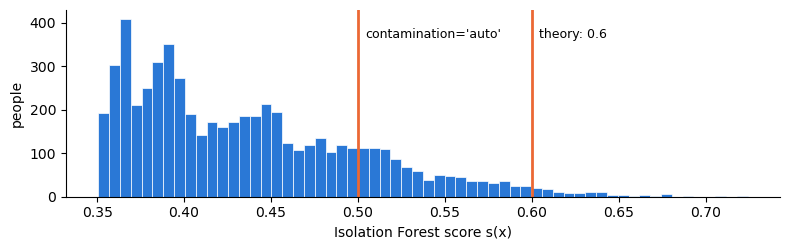

In [3]:
iso = IsolationForest(random_state=42).fit(Z)
s_if = -iso.score_samples(Z)                 # the theory's s(x)

print(f"s(x) from {s_if.min():.2f} to {s_if.max():.2f}, median {np.median(s_if):.2f}")
print(f"s(x) >= 0.6 (theory's rule)          : {(s_if >= 0.6).sum():4d} people")
print(f"predict() == -1, contamination='auto': {(iso.predict(Z) == -1).sum():4d} people  (that's s(x) > 0.5)")

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.hist(s_if, bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
for cut, label in [(0.5, "contamination='auto'"), (0.6, "theory: 0.6")]:
    ax.axvline(cut, color=ORANGE, linewidth=2)
    ax.text(cut + 0.004, ax.get_ylim()[1] * 0.85, label, fontsize=9)
ax.set_xlabel("Isolation Forest score s(x)")
ax.set_ylabel("people")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()

In [4]:
top_if = np.argsort(-s_if)[:10]
X_dev.iloc[top_if][show].assign(score=s_if[top_if].round(3))

,age,juv_fel_count,juv_misd_count,juv_other_count,priors_count,sex,c_charge_degree,score
2155,37.0,1.0,8,5,23.0,Male,F,0.724
2408,20.0,4.0,2,1,6.0,Male,NaN,0.705
4677,18.0,5.0,0,2,4.0,Male,NaN,0.687
2161,19.0,1.0,3,2,5.0,Male,M,0.680
1990,23.0,1.0,2,2,NaN,Male,F,0.679
122,32.0,0.0,6,5,17.0,Male,F,0.678
2829,35.0,0.0,4,17,12.0,Male,F,0.677
5259,24.0,0.0,5,1,15.0,Male,NaN,0.676
1504,27.0,0.0,5,1,27.0,Male,M,0.676
1510,34.0,2.0,1,3,21.0,Male,F,0.674


The most isolated people combine **many juvenile records with many priors**: rare combinations, easy to cut off with a few random splits.

## 4 · LOF in scikit-learn: three practical points

![LOF](images/lof.png)

**1. It needs scaled columns.** LOF compares distances, so the column with the biggest range would decide everything. In the pipeline it runs after the preprocessor, so `Z` is already scaled.

**2. Scoring new people needs `novelty=True`.**

| | `novelty=False` (default) | `novelty=True` |
|---|---|---|
| What it does | scores only the rows it was fitted on (`negative_outlier_factor_`) | also scores **new** rows (`score_samples`) |
| In `predict.py` | ❌ can't score a new person | ✅ |

With `novelty=True`, the training rows still get their proper LOF in `negative_outlier_factor_`. `score_samples` on the *training* rows would count each row as its own neighbour, so we don't use it for them.

In [5]:
lof = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(Z)
lof_train = -lof.negative_outlier_factor_          # LOF of the training rows (≈ 1 ordinary, >> 1 anomaly)
lof_new = -lof.score_samples(prep.transform(X_dev.head(3)))   # how new rows are scored

print("LOF percentiles 50/90/99/max:", np.percentile(lof_train, [50, 90, 99, 100]).round(2))
print("LOF > 1.5:", (lof_train > 1.5).sum(), "people")

LOF percentiles 50/90/99/max: [ 1.02  1.44  4.56 14.26]
LOF > 1.5: 483 people


**3. Choosing *k* (`n_neighbors`).** The theory: try several values; robust outliers are high for every *k*.

🤔 **Guess first:** which *k* will behave strangely on COMPAS: 5, 20 or 50?

In [6]:
lof_k = {k: -LocalOutlierFactor(n_neighbors=k).fit(Z).negative_outlier_factor_ for k in [5, 20, 50]}
print(pd.DataFrame({f"k = {k}": np.percentile(v, [50, 99, 100]) for k, v in lof_k.items()},
                   index=["median", "99th percentile", "max"]).map(lambda v: f"{v:,.1f}"))

_, counts = np.unique(Z.round(6), axis=0, return_counts=True)
print(f"\nlargest group of identical people: {counts.max()}")

                         k = 5 k = 20 k = 50
median                     1.0    1.0    1.0
99th percentile   30,332,986.0    4.6    2.8
max              844,504,565.2   14.3    8.9

largest group of identical people: 14


With *k* = 5 the scores explode to hundreds of millions. COMPAS has **groups of up to 14 identical people** (same age, counts, sex, charge). If *k* is smaller than such a group, a row's *k* nearest neighbours are all at distance 0: its density is "infinite", and its neighbours' LOF blows up. **Rule: `n_neighbors` larger than the largest group of identical rows.** Our default, 20, is.

In [7]:
robust = (lof_k[20] > 1.5) & (lof_k[50] > 1.5)
print(f"LOF > 1.5 for k = 20: {(lof_k[20] > 1.5).sum()}  ·  k = 50: {(lof_k[50] > 1.5).sum()}  ·  both: {robust.sum()}")

LOF > 1.5 for k = 20: 483  ·  k = 50: 486  ·  both: 217


## 5 · Do Isolation Forest and LOF agree?

In [8]:
top_lof = np.argsort(-lof_train)[:10]
print("people in both top 10s:", len(set(top_if) & set(top_lof)))
print("rank correlation of the two scores:", round(pd.Series(s_if).corr(pd.Series(lof_train), method="spearman"), 2))
X_dev.iloc[top_lof][show].assign(lof=lof_train[top_lof].round(1))

people in both top 10s: 0
rank correlation of the two scores: 0.34


,age,juv_fel_count,juv_misd_count,juv_other_count,priors_count,sex,c_charge_degree,lof
5306,51.0,1.0,0,0,NaN,Male,F,14.3
5946,24.0,0.0,0,0,1.0,Female,F,14.0
7228,21.0,0.0,0,0,1.0,Male,M,13.9
2931,21.0,0.0,0,0,1.0,Male,M,13.9
3901,NaN,0.0,0,0,0.0,Male,F,13.2
4172,NaN,0.0,0,0,0.0,Male,F,13.1
2259,24.0,0.0,0,0,1.0,Female,F,12.9
1876,24.0,0.0,0,0,1.0,Female,F,12.9
5559,24.0,NaN,0,0,1.0,Female,F,12.9
6391,NaN,0.0,0,0,1.0,Male,F,11.7


**No overlap at all.** They answer different questions:
- **Isolation Forest** (global): who is far from *everyone*? Extreme combinations of counts.
- **LOF** (local): who sits in a sparser spot than *their neighbours*? Here, often people right next to a tight group of near-identical people (young, 1 prior), so their neighbourhood looks dense and they look sparse by comparison.

And **flagged ≠ wrong**: none of these rows is an error.

## 6 · Three things to do with an anomaly, and where each goes

| Option | What it does | Where it goes |
|---|---|---|
| **Keep it, add its score as a feature** | the model can use "how unusual" | a step **inside the Pipeline**, fitted on each fold's training rows, so it also scores new people |
| **Drop it from training only** | the model doesn't learn from odd rows | a fit-only step: removed from the training rows of each fold, **never** from validation or new people (every person needs a prediction) |
| **Cap the column** | an extreme value is pulled back to a limit | a transformer that learns the limits (e.g. quantiles) on the training rows |

All three are **learned from data**, so all three go inside the Pipeline. Fitting a detector on all rows and then cross-validating would leak, exactly like an imputer fitted before the split.

We add the first one to the pipeline; the other two are challenges.

## 7 · 🆕 `AnomalyScore`

![Where the anomaly score lives](images/anomaly_in_pipeline.png)

Step by step, on `Z`: fit a detector on the training rows, then append its score as one more column.

In [9]:
detector = IsolationForest(random_state=42).fit(Z)         # fit: training rows only
Z_plus = np.column_stack([Z, -detector.score_samples(Z)])  # transform: one more column
print(Z.shape, "->", Z_plus.shape)

(5771, 10) -> (5771, 11)


It **learns** something (the forest, or the neighbourhoods), so it is a **class** following the scikit-learn contract, like `VoteSelector`. This is the version that goes in `src/preprocessing.py`:

In [10]:
class AnomalyScore(TransformerMixin, BaseEstimator):
    """
    Appends one column, `anomaly_score`, to the preprocessed features: how unusual each row is
    compared with the training rows (higher = more unusual). `method` is "isolation_forest"
    (the score is the theory's s(x), about 0.5 for ordinary rows and close to 1 for anomalies)
    or "lof" (the Local Outlier Factor, about 1 for ordinary rows; `n_neighbors` should be
    larger than the largest group of identical rows). The detector is fitted on the training
    rows only and then scores any rows, so it runs unchanged in CV and on data to predict.
    """

    def __init__(self, method: str = "isolation_forest", n_neighbors: int = 20, random_state=None):
        self.method = method
        self.n_neighbors = n_neighbors
        self.random_state = random_state

    def fit(self, X, y=None):
        if self.method == "isolation_forest":
            self.detector_ = IsolationForest(random_state=self.random_state)
        elif self.method == "lof":
            self.detector_ = LocalOutlierFactor(n_neighbors=self.n_neighbors, novelty=True)
        else:
            raise ValueError(f"Unknown anomaly method: {self.method}. Options: isolation_forest, lof")
        self.detector_.fit(X)
        self.n_features_in_ = np.asarray(X).shape[1]
        return self

    def fit_transform(self, X, y=None):
        """Fits on X and scores it. LOF scores its own training rows without counting each row as its own neighbour."""
        self.fit(X)
        if self.method == "lof":
            return np.column_stack([X, -self.detector_.negative_outlier_factor_])
        return self.transform(X)

    def transform(self, X):
        return np.column_stack([X, -self.detector_.score_samples(X)])

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            input_features = [f"x{i}" for i in range(self.n_features_in_)]
        return np.append(np.asarray(input_features, dtype=object), "anomaly_score")

- `fit` / `transform`: the training rows teach the detector; any rows (validation, new people) are scored.
- `fit_transform`: what the Pipeline calls on the training rows. For LOF it uses the proper training-row LOF (point 2 above).
- `get_feature_names_out`: so the feature names still work after the step (feature selection prints them).
- `contamination` isn't needed: it only moves the yes/no cut, and we keep the score itself.

The config section it reads (new in `config.yaml`):

In [11]:
anomaly_config = {
    "method": "isolation_forest",    # none | isolation_forest | lof
    "n_neighbors": 20,               # lof: larger than the largest group of identical rows
    "random_state": 42,              # isolation_forest
}

🔄 **`build_pipeline()`** (in `src/model.py`) gets an `anomaly_config` argument and places the step right after `"prep"`, before feature selection (so selection can keep or drop the score):

In [12]:
def build_pipeline(preprocessing_config: dict, model_config: dict, selection_config: dict = None,
                   memory=None, anomaly_config: dict = None) -> Pipeline:
    """
    The estimator that is cross-validated, tuned and refit: preprocessing, the anomaly score
    (if `anomaly_config["method"]` is not "none"), feature selection (if
    `selection_config["enabled"]`) and model as one Pipeline, so every learned step is re-fit
    on the training part of each fold. Step names address hyperparameters from outside
    (`model__max_depth`, `select__min_votes`, `anomaly__n_neighbors`). `memory` (a folder)
    caches the fitted preprocessing, anomaly and selection steps: a fit on the same rows with
    the same settings is reused instead of repeated, so tuning the model doesn't refit them in
    every trial.
    """
    steps = [("prep", build_preprocessor(preprocessing_config))]
    if anomaly_config and anomaly_config.get("method", "none") != "none":
        steps.append(("anomaly", AnomalyScore(method=anomaly_config["method"],
                                              n_neighbors=anomaly_config.get("n_neighbors", 20),
                                              random_state=anomaly_config.get("random_state"))))
    if selection_config and selection_config.get("enabled", False):
        steps.append(("select", VoteSelector(min_votes=selection_config.get("min_votes", 2),
                                             random_state=selection_config.get("random_state"))))
    steps.append(("model", build_model(model_config)))
    return Pipeline(steps, memory=memory)

In [13]:
pipe = build_pipeline(CONFIG["preprocessing"], CONFIG["model"], CONFIG["feature_selection"],
                      anomaly_config=anomaly_config)
print([name for name, _ in pipe.steps])

['prep', 'anomaly', 'select', 'model']


## 8 · Adding it to your pipeline

| File | Change |
|---|---|
| `src/preprocessing.py` | 🆕 the `AnomalyScore` class (imports: `BaseEstimator`, `TransformerMixin`, `IsolationForest`, `LocalOutlierFactor`) |
| `src/model.py` | 🔄 `build_pipeline(..., anomaly_config=None)` as above; import `AnomalyScore` |
| `config.yaml` | 🆕 the `anomaly` section (`method: "none"` by default) |
| `main.py` | 🔄 pass `anomaly_config=config.get("anomaly")` to `build_pipeline`; add `"anomaly"` to the runs row and the scoreboard columns; if you print the kept features, pass the names through the `"anomaly"` step's `get_feature_names_out` |
| `predict.py` | nothing: the saved Pipeline already contains the fitted detector |

Then, from the project folder:
```bash
python main.py                                         # method: "none"
python main.py                                         # method: "isolation_forest"
python main.py                                         # method: "lof"
python predict.py data/compas_new_people.csv predictions.csv
```
Tip: set `tuning.enabled: false` while you compare the three methods, so each run takes seconds.

**Comparing runs:** the scoreboard in `results/runs.csv` ranks every run on the same data, *whatever its preprocessing*. It now records the anomaly method, but to measure what **one** setting adds, compare two runs that differ only in that setting, on the same folds, with `corrected_paired_test()`.

**What this notebook adds to the pipeline:** an `AnomalyScore` step (Isolation Forest or LOF, fitted on each fold's training rows) that appends how unusual each person is as a feature, switched on in `config.yaml`.

## 🏁 Challenges

**Required steps** (in your own pipeline):
1. Add the `AnomalyScore` class to `src/preprocessing.py` and the `anomaly_config` argument to `build_pipeline()`.
2. Add the `anomaly` section to `config.yaml` and pass it from `main.py`; record the method in the runs row.
3. Check `predict.py` still returns 20 rows for `data/compas_new_people.csv`.
4. 🤔 **Does it help on COMPAS?** Before running anything, write your guess in the README: will the anomaly score improve the model? Are the people who reoffend the outliers?
   - Then check: how often do the most unusual people (e.g. the top 5% by score) reoffend, compared with everyone else?
   - Run `main.py` three times (`none`, `isolation_forest`, `lof`).
   - README: was your guess right? Did the score help, and why (or why not)?

**Other challenges:**
- **Drop anomalies from training only.** For example, you can use `pip install imbalanced-learn`, then use `FunctionSampler` inside an `imblearn.pipeline.Pipeline`: a sampler only acts during `fit`, so it removes the most anomalous training rows of each fold and never touches validation rows or new people. Does it help?
- **Cap instead of score.** Write a `QuantileClipper` (learns the 1st and 99th percentile of each numeric column on the training rows and clips to them), or try `log1p` on the count columns. Compare with the same folds.
- **Tune *k*.** Add `anomaly__n_neighbors` to the search space (low: 20). Does nested CV move?

**This week's additions to the pipeline:** the `AnomalyScore` step, the `anomaly` section in `config.yaml`, and the anomaly method in the runs table and report.